# 01 — Toy Pong, visually

<div><span style="display:inline-block;background:#334155;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">ENVIRONMENT</span><span style="display:inline-block;background:#1F3A93;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">REPRESENTATION</span><span style="display:inline-block;background:#0F766E;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">POLICY</span><span style="display:inline-block;background:#F58518;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">ACTION</span><span style="display:inline-block;background:#17BECF;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">OBSERVATION</span><span style="display:inline-block;background:#4C78A8;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">STATE</span><span style="display:inline-block;background:#54A24B;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">REWARD</span></div>

Same RL loop, but now the state has several numbers at once: paddle position, ball position, and ball velocity.

You will see why **state representation** starts to matter.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-010" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Toy Pong</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#334155" stroke="#334155" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">BALL + PADDLES</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-010)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">NUMERIC STATE</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-010)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">POLICY</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-010)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">UP / STAY / DOWN</text>
</svg>
</div>


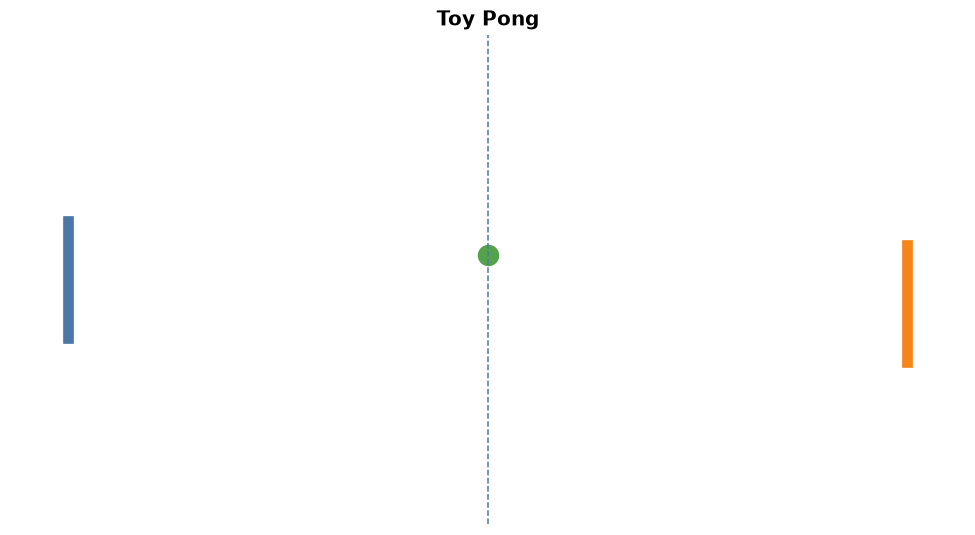

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
repo = Path.cwd()
if repo.name == "notebooks": repo = repo.parent
sys.path.insert(0, str(repo))
from visuals import pipeline, compare_bars, COLORS

def draw_pong(player_y=0.5, ball_x=0.5, ball_y=0.55, opp_y=0.45, title="Toy Pong"):
    fig, ax = plt.subplots(figsize=(9,5))
    ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis("off")
    ax.plot([0.06,0.06],[player_y-0.12,player_y+0.12], linewidth=7, color=COLORS["STATE"])
    ax.plot([0.94,0.94],[opp_y-0.12,opp_y+0.12], linewidth=7, color=COLORS["ACTION"])
    ax.scatter([ball_x],[ball_y],s=170, color=COLORS["REWARD"])
    ax.axvline(0.5, linestyle="--", linewidth=1)
    ax.set_title(title)
    plt.tight_layout()
    return fig

fig = draw_pong()
plt.show()

<div style="border-left:10px solid #4C78A8;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#4C78A8">STATE</div><div style="font-size:21px;font-weight:800;margin-top:4px">1. A useful engineered state</div></div>

Instead of pixels, we can hand the policy a compact vector:

`[player_y, ball_x, ball_y, ball_vx, ball_vy, opponent_y]`.

That is already a **state representation choice**.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-012" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Engineered representation</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">RAW GAME</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-012)"/>
<rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">6 NUMBERS</text>
<line x1="480.0" y1="82" x2="617.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-012)"/>
<rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">POLICY</text>
</svg>
</div>


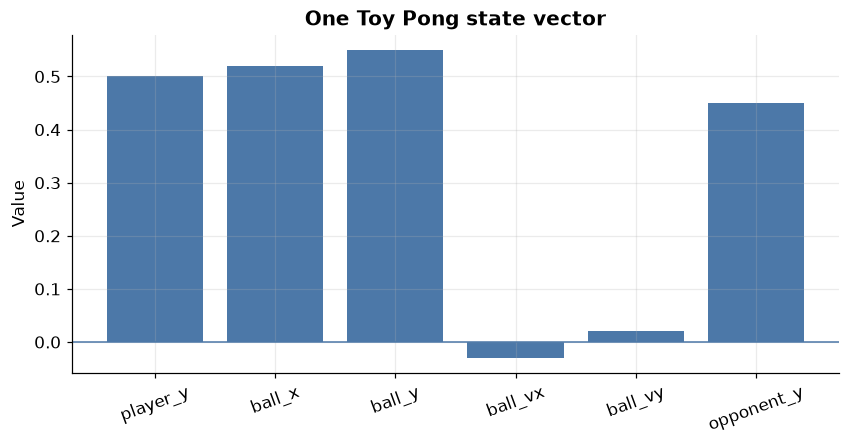

In [2]:
state = np.array([0.50, 0.52, 0.55, -0.03, 0.02, 0.45])
labels = ["player_y","ball_x","ball_y","ball_vx","ball_vy","opponent_y"]

plt.figure(figsize=(9,4))
plt.bar(labels, state, color=COLORS["STATE"])
plt.axhline(0, linewidth=1)
plt.xticks(rotation=20)
plt.ylabel("Value")
plt.title("One Toy Pong state vector")
plt.show()

<div style="border-left:10px solid #4C78A8;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#4C78A8">STATE</div><div style="font-size:21px;font-weight:800;margin-top:4px">2. Why velocity matters</div></div>

One still ball position does not tell you whether the ball is arriving or leaving.

Two worlds can have the **same ball position** but require different actions because velocity differs.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-014" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Hidden consequence of dropping velocity</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#4C78A8" stroke="#4C78A8" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">SAME POSITION</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-014)"/>
<rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="#64748B" stroke="#64748B" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">vx &lt; 0: COMING</text>
<line x1="480.0" y1="82" x2="617.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-014)"/>
<rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="#64748B" stroke="#64748B" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">vx &gt; 0: LEAVING</text>
</svg>
</div>


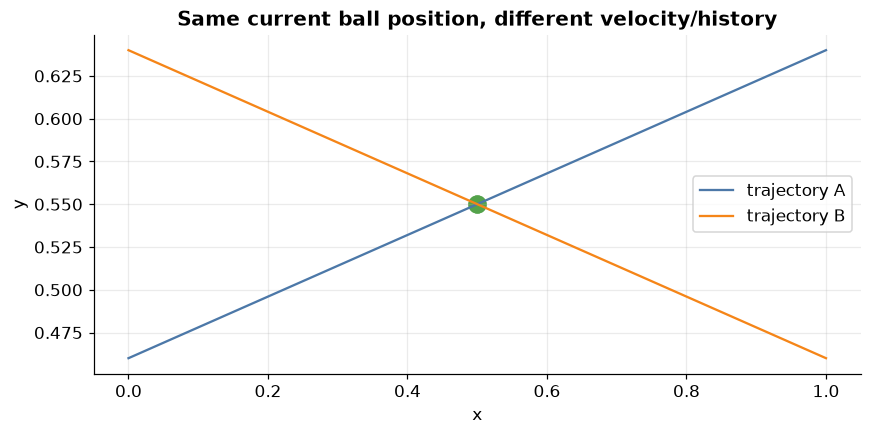

In [3]:
x = np.linspace(0,1,30)
coming = 0.55 + 0.18*(x-0.5)
leaving = 0.55 - 0.18*(x-0.5)

plt.figure(figsize=(9,4))
plt.plot(x, coming, label="trajectory A", color=COLORS["STATE"])
plt.plot(x, leaving, label="trajectory B", color=COLORS["ACTION"])
plt.scatter([0.5,0.5],[0.55,0.55],s=120, color=COLORS["REWARD"])
plt.xlabel("x")
plt.ylabel("y")
plt.title("Same current ball position, different velocity/history")
plt.legend()
plt.show()

<div style="border-left:10px solid #0F766E;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#0F766E">POLICY</div><div style="font-size:21px;font-weight:800;margin-top:4px">3. Policy output</div></div>

Toy Pong has three actions: `UP`, `STAY`, `DOWN`.

A learned policy maps the represented state to a preference or probability for each action.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-016" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Policy output</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">STATE VECTOR</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-016)"/>
<rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">POLICY</text>
<line x1="480.0" y1="82" x2="617.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-016)"/>
<rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">UP / STAY / DOWN</text>
</svg>
</div>


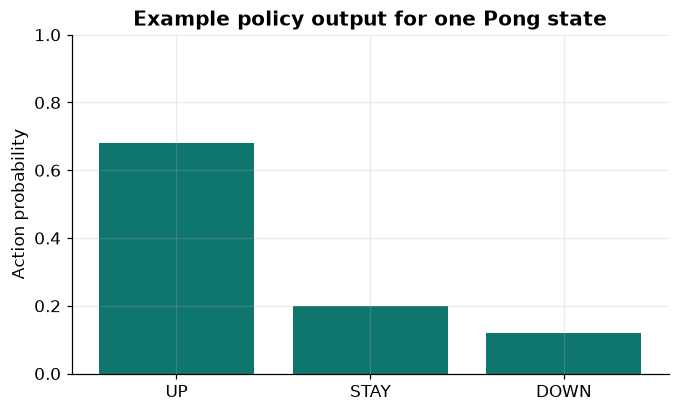

In [4]:
actions = ["UP","STAY","DOWN"]
example_probs = [0.68, 0.20, 0.12]

plt.figure(figsize=(7,4))
plt.bar(actions, example_probs, color=COLORS["POLICY"])
plt.ylim(0,1)
plt.ylabel("Action probability")
plt.title("Example policy output for one Pong state")
plt.show()

<div style="border-left:10px solid #4C78A8;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#4C78A8">STATE</div><div style="font-size:21px;font-weight:800;margin-top:4px">4. State ablation</div></div>

Now do the thing Fatimah cares about: keep the task and learner fixed, but remove information.

- FULL: position + velocity
- NO VELOCITY: hide velocity
- MINIMAL: only player + ball position

If performance drops, the removed information was decision-relevant.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-018" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Ablation experiment</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">FULL</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-018)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">NO VELOCITY</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-018)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">MINIMAL</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-018)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">COMPARE OUTCOMES</text>
</svg>
</div>


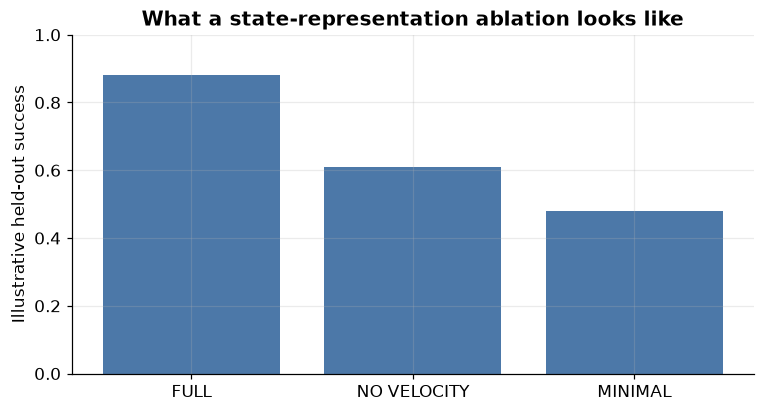

These bars illustrate the experimental logic; run extras/pong/compare_states.py for actual training.


In [5]:
labels = ["FULL","NO VELOCITY","MINIMAL"]
illustrative_success = [0.88, 0.61, 0.48]

plt.figure(figsize=(8,4))
plt.bar(labels, illustrative_success, color=COLORS["STATE"])
plt.ylim(0,1)
plt.ylabel("Illustrative held-out success")
plt.title("What a state-representation ablation looks like")
plt.show()

print("These bars illustrate the experimental logic; run extras/pong/compare_states.py for actual training.")

<div style="border-left:10px solid #334155;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#334155">ENVIRONMENT</div><div style="font-size:21px;font-weight:800;margin-top:4px">5. Run the actual Toy Pong code later</div></div>

The repo includes `extras/pong/` with manual play, training, watching, and state comparison.

The conceptual question is now simple:

> Which information must remain distinguishable so the policy can choose correctly?

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-0110" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Same research loop</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">OBSERVATION</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0110)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">REPRESENTATION</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0110)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">POLICY</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0110)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">OUTCOME</text>
</svg>
</div>
